In [1]:
import torch 
import torch.nn as nn 
torch.manual_seed(42)


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.3 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/opt/homebrew/Caskroom/miniconda/base/envs/learning/lib/python3.12/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/opt/homebrew/Caskroom/miniconda/base/envs/learning/lib/python3.12/site-packages/traitlets/config/application.py", line 1080, in launch_instance
    app.start()
  File "/opt/homebrew/Caskroom/miniconda/base/envs/learning/lib/python3.12/site-packages/i

In [2]:
batch_size = 1
seq_length = 3
embedding_dim = 3
input = torch.randint(
    high = 2,
    size = (batch_size, seq_length, embedding_dim),
    dtype = torch.float32
)
print(input)

tensor([[[0., 1., 0.],
         [0., 0., 1.],
         [0., 0., 0.]]])


In [3]:
hidden_size = 2
activation = 'relu'

rnn_layer = nn.RNN(
    input_size = embedding_dim,
    hidden_size = hidden_size,
    nonlinearity = activation,
    batch_first = True
)

print(rnn_layer.all_weights)

[[Parameter containing:
tensor([[-0.5188,  0.6146,  0.1323],
        [ 0.5224,  0.0958,  0.3410]], requires_grad=True), Parameter containing:
tensor([[-0.0998,  0.5451],
        [ 0.1045, -0.3301]], requires_grad=True), Parameter containing:
tensor([ 0.1802, -0.3258], requires_grad=True), Parameter containing:
tensor([-0.0829, -0.2872], requires_grad=True)]]


In [4]:
for param in rnn_layer.parameters():
    init_kernel_weight = torch.randint(
        high = 2,
        size = (param.data.shape),
        dtype = torch.float32
    )
    print(param.data.shape)
    param.data = init_kernel_weight

torch.Size([2, 3])
torch.Size([2, 2])
torch.Size([2])
torch.Size([2])


In [5]:
for name, param in rnn_layer.named_parameters():
    print(name, param)

weight_ih_l0 Parameter containing:
tensor([[1., 1., 1.],
        [1., 1., 1.]], requires_grad=True)
weight_hh_l0 Parameter containing:
tensor([[1., 0.],
        [0., 1.]], requires_grad=True)
bias_ih_l0 Parameter containing:
tensor([1., 1.], requires_grad=True)
bias_hh_l0 Parameter containing:
tensor([0., 1.], requires_grad=True)


<div>Example 1</div>

In [6]:
output, hn = rnn_layer(input) #khong khoi tao h0, nhung mac dinh se la [0, 0]
output

tensor([[[2., 3.],
         [4., 6.],
         [5., 8.]]], grad_fn=<TransposeBackward1>)

In [7]:
hn

tensor([[[5., 8.]]], grad_fn=<StackBackward0>)

<div>Example 2</div>

In [8]:
# khoi tao h0
h0 = torch.randint(
    high = 2,
    size = (1, batch_size, hidden_size),
    dtype = torch.float32
)

In [9]:
print(h0)
print(h0.shape)

tensor([[[0., 0.]]])
torch.Size([1, 1, 2])


In [10]:
output, hn = rnn_layer(input, h0)

In [11]:
output

tensor([[[2., 3.],
         [4., 6.],
         [5., 8.]]], grad_fn=<TransposeBackward1>)

In [12]:
hn

tensor([[[5., 8.]]], grad_fn=<StackBackward0>)

<h1>Example 3</h1>

In [13]:
from torchtext.data.utils import get_tokenizer
from torchtext.vocab import build_vocab_from_iterator

data = ['dog bites man', 'man bites dog', 'dog eats meat', 'man eats food']

# Define the max vocabulary size
vocab_size = 7

tokenizer = get_tokenizer('basic_english')

# Define a fucntion to yield list of tokens
def yield_tokens(examples):
    for text in examples:
        yield tokenizer(text)

# Create vocabulary
vocab = build_vocab_from_iterator(
    yield_tokens(data),
    max_tokens = vocab_size,
    specials=['<unk>']
)
vocab.set_default_index(vocab['<unk>'])
vocab.get_stoi()

{'meat': 6, 'food': 5, 'eats': 4, 'man': 2, 'bites': 3, 'dog': 1, '<unk>': 0}

In [14]:
data = 'dog bites man'
print(tokenizer(data))
print(vocab(tokenizer(data)))

['dog', 'bites', 'man']
[1, 3, 2]


In [15]:
input = torch.tensor(vocab(tokenizer('dog bites man')))
input

tensor([1, 3, 2])

In [16]:
input = input.unsqueeze(0)
print(input)

tensor([[1, 3, 2]])


In [17]:
from torch import nn 
embedding = nn.Embedding(
    num_embeddings = vocab_size,
    embedding_dim = 10
)
print(embedding.weight)

Parameter containing:
tensor([[-0.7746,  0.0349,  0.3211,  1.5736, -0.8455,  1.3123,  0.6872, -1.0892,
         -0.4879, -1.4181],
        [ 0.8963,  0.0499,  2.2667,  1.1790, -0.4345, -1.3864, -0.7360, -0.8371,
         -0.9224,  1.8113],
        [ 0.1606,  0.3672,  0.1754,  1.3852,  1.3835, -1.2024,  0.7078, -1.0759,
          0.5357,  1.1754],
        [ 0.5612, -0.4527,  1.2780,  0.1453,  0.2311,  0.0087, -0.1423,  0.1971,
         -1.1441,  0.3383],
        [-0.7508,  2.8140,  0.3598, -0.0898,  0.4584, -0.5644,  1.0563, -1.4692,
          0.0516,  0.7281],
        [-0.7106, -0.6021,  0.9604,  0.4048,  0.5886, -0.8905,  0.4098, -1.4570,
         -0.1023, -0.5992],
        [ 0.4771,  0.7262,  0.2332,  4.0356,  1.2795, -0.0127,  0.2408,  0.1325,
          0.7642,  1.0950]], requires_grad=True)


In [18]:
embedded = embedding(input)

In [19]:
embedding_dim = 10
hidden_size = 5 
activation = 'relu'
rnn_layer = nn.RNN(
    input_size = embedding_dim,
    hidden_size = hidden_size,
    nonlinearity = activation,
    batch_first = True
)

In [20]:
output, hn = rnn_layer(embedded)

In [21]:
output

tensor([[[0.0000, 0.0000, 2.5971, 0.3983, 0.9179],
         [0.0000, 0.0000, 0.6947, 1.2723, 0.8154],
         [0.0000, 0.0000, 0.1273, 0.1378, 0.0000]]],
       grad_fn=<TransposeBackward1>)

<h1>Text Classification</h1>

In [22]:
# !git clone https://github.com/congnghia0609/ntc-scv.git

In [ ]:
# !unzip ./ntc-scv/data/data_test.zip -d ./data
# !unzip ./ntc-scv/data/data_train.zip -d ./data
# !rm -rf ./ntc-scv

In [2]:
import os 
import pandas as pd 
def load_data_from_path(folder_path):
    examples = []
    for label in os.listdir(folder_path):
        full_path = os.path.join(folder_path, label)
        for file_name in os.listdir(full_path):
            file_path = os.path.join(full_path, file_name)
            with open(file_path, 'r', encoding = 'utf-8') as f:
                lines = f.readlines()
                sentence = " ".join(lines)
                if label == 'neg':
                    label = 0
                if label == 'pos':
                    label = 1
                data = {
                    'sentence': sentence,
                    'label': label
                }
                examples.append(data)
    return pd.DataFrame(examples)


folder_paths = {
    'train': './data/data_train/train',
    'valid' : './data/data_train/test',
    'test': './data/data_test/test'
}
train_df = load_data_from_path(folder_paths['train'])
valid_df = load_data_from_path(folder_paths['valid'])
test_df = load_data_from_path(folder_paths['test'])

<h2>Preprocessing</h2>

<div>Language Detection</div>

In [3]:
from langid.langid import LanguageIdentifier, model
def identify_vn(df):
    identifier = LanguageIdentifier.from_modelstring(model, norm_probs = True)
    not_vi_idx = set()
    THRESHOLD = 0.9
    for idx, row in df.iterrows():
        score = identifier.classify(row['sentence'])
        if score[0] != 'vi' or (score[0] == 'vi' and score[1] <= THRESHOLD):
            not_vi_idx.add(idx)
    vi_df = df[~df.index.isin(not_vi_idx)]
    not_vi_df = df[df.index.isin(not_vi_idx)]
    return vi_df, not_vi_df 


train_df_vi, train_df_other = identify_vn(train_df)

<div>Text Cleaning</div>

In [4]:
import re
import string

def preprocess_text(text):
    # remove URLs https://www.
    url_pattern = re.compile(r'https?://\s+\wwww\.\s+')
    text = url_pattern.sub(r" ", text)

    # remove HTML Tags: <>
    html_pattern = re.compile(r'<[^<>]+>')
    text = html_pattern.sub(" ", text)

    # remove puncs and digits
    replace_chars = list(string.punctuation + string.digits)
    for char in replace_chars:
        text = text.replace(char, " ")

    # remove emoji
    emoji_pattern = re.compile("["
        u"\U0001F600-\U0001F64F"  # emoticons
        u"\U0001F300-\U0001F5FF"  # symbols & pictographs
        u"\U0001F680-\U0001F6FF"  # transport & map symbols
        u"\U0001F1E0-\U0001F1FF"  # flags (iOS)
        u"\U0001F1F2-\U0001F1F4"  # Macau flag
        u"\U0001F1E6-\U0001F1FF"  # flags
        u"\U0001F600-\U0001F64F"
        u"\U00002702-\U000027B0"
        u"\U000024C2-\U0001F251"
        u"\U0001f926-\U0001f937"
        u"\U0001F1F2"
        u"\U0001F1F4"
        u"\U0001F620"
        u"\u200d"
        u"\u2640-\u2642"
        "]+", flags=re.UNICODE)
    text = emoji_pattern.sub(r" ", text)

    # normalize whitespace
    text = " ".join(text.split())

    # lowercasing
    text = text.lower()
    return text

In [5]:
train_df_vi['preprocess_sentence'] = [preprocess_text(row['sentence']) for index, row in train_df_vi.iterrows()]
valid_df['preprocess_sentence'] = [preprocess_text(row['sentence']) for index, row in valid_df.iterrows()]
test_df['preprocess_sentence'] = [preprocess_text(row['sentence']) for index, row in test_df.iterrows()]

In [6]:
train_df_vi

,sentence,label,preprocess_sentence
0,Quán đồ_ăn khá ngon . . nhưng phục_vụ không tố...,0,quán đồ ăn khá ngon nhưng phục vụ không tốt ch...
1,"Hôm_nay đi ăn tại quán , món ăn ngon vừa_miệng...",0,hôm nay đi ăn tại quán món ăn ngon vừa miệng k...
2,Qua ́ n cư ̣ c ngon . Tuâ ̀ n na ̀ o mi ̀ nh c...,0,qua ́ n cư ̣ c ngon tuâ ̀ n na ̀ o mi ̀ nh cu ...
3,"Chán , đồ uống khá nhạt . Với không_gian và ch...",0,chán đồ uống khá nhạt với không gian và chất l...
4,"Mì ăn ok 👍 🏻 👍 🏻 👍 🏻 nhưng nguội , view rộng ,...",0,mì ăn ok nhưng nguội view rộng nhưng kêu món v...
...,...,...,...
29995,"Giáo_viên dạy tận_tình , chất_lượng tốt , giá_...",1,giáo viên dạy tận tình chất lượng tốt giá cả r...
29996,Chô ̃ gư ̉ i xe_hơi bâ ́ t tiê ̣ n đi khoa ̉ n...,1,chô ̃ gư ̉ i xe hơi bâ ́ t tiê ̣ n đi khoa ̉ n...
29997,Quán nằm trong đường hơi khó tìm nhưng bù lại ...,1,quán nằm trong đường hơi khó tìm nhưng bù lại ...
29998,Mình dùng deal khi tới đây nhưng nhân_viên vẫn...,1,mình dùng deal khi tới đây nhưng nhân viên vẫn...


In [7]:
def yield_tokens(sentences, tokenizer):
    for sentence in sentences:
        yield tokenizer(sentence)

In [8]:
from torchtext.vocab import build_vocab_from_iterator
from torchtext.data.utils import get_tokenizer
tokenizer = get_tokenizer('basic_english')
vocab_size = 10000
vocabulary = build_vocab_from_iterator(
    yield_tokens(train_df_vi['preprocess_sentence'], tokenizer),
    max_tokens = vocab_size,
    specials = ['<pad>', '<unk>']
)
vocabulary.set_default_index(vocabulary['<unk>'])


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.3 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/opt/homebrew/Caskroom/miniconda/base/envs/learning/lib/python3.12/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/opt/homebrew/Caskroom/miniconda/base/envs/learning/lib/python3.12/site-packages/traitlets/config/application.py", line 1080, in launch_instance
    app.start()
  File "/opt/homebrew/Caskroom/miniconda/base/envs/learning/lib/python3.12/site-packages/i

In [16]:
from torchtext.data.functional import to_map_style_dataset
def prepare_dataset(df):
    for index, row in df.iterrows():
        sentence = row['preprocess_sentence']
        encoded_sentence = vocabulary(tokenizer(sentence))
        label = row['label']
        yield encoded_sentence, label
train_dataset = prepare_dataset(train_df_vi)
train_dataset = to_map_style_dataset(train_dataset)

valid_dataset = prepare_dataset(valid_df)
valid_dataset = to_map_style_dataset(valid_dataset)

test_dataset = prepare_dataset(test_df)
test_dataset = to_map_style_dataset(test_dataset)

<div>Dataloader</div>

In [17]:
seq_length = 50
def collate_batch(batch):
    sentences, labels = list(zip(*batch))
    encoded_sentences = [
        sentence + ([0] * (seq_length - len(sentence))) if len(sentence) < seq_length else sentence[:seq_length]
        for sentence in sentences
    ]
    encoded_sentences = torch.tensor(encoded_sentences, dtype = torch.int64)
    labels = torch.tensor(labels)
    return encoded_sentences, labels

In [18]:
from torch.utils.data import DataLoader
batch_size = 128
train_dataloader = DataLoader(
    train_dataset,
    shuffle = True,
    batch_size = batch_size,
    collate_fn = collate_batch
)
valid_dataloader = DataLoader(
    valid_dataset,
    shuffle = False,
    batch_size = batch_size,
    collate_fn = collate_batch
)
test_dataloader = DataLoader(
    test_dataset,
    shuffle = False,
    batch_size = batch_size,
    collate_fn = collate_batch
)

In [20]:
import torch
next(iter(train_dataloader))

(tensor([[568, 110,  17,  ...,   0,   0,   0],
         [  7, 144, 460,  ...,   0,   0,   0],
         [  7,  11, 275,  ...,   0,   0,   0],
         ...,
         [  3,   2, 234,  ..., 178,   8, 208],
         [284,  77,  17,  ...,   0,   0,   0],
         [  7,  13, 266,  ...,   0,   0,   0]]),
 tensor([0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1,
         1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1,
         0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0,
         1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0,
         1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1,
         0, 0, 1, 1, 0, 0, 0, 1]))

In [21]:
len(train_dataloader)

233

In [22]:
encoded_sentences, labels = next(iter(train_dataloader))
print(encoded_sentences.shape)
print(labels.shape)

torch.Size([128, 50])
torch.Size([128])


<div>Trainer</div>

In [45]:
import time 
def train_epoch(model, optimizer, criterion, train_dataloder, device, epoch = 0, log_interval = 50):
    model.train()
    total_acc, total_count = 0, 0
    losses = []
    start_time = time.time()
    for idx, (inputs, labels) in enumerate(train_dataloader):
        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        predictions = model(inputs, device)

        loss = criterion(predictions, labels)
        losses.append(loss.item())

        loss.backward()
        optimizer.step()
        total_acc += (predictions.argmax(1) == labels).sum().item()

        total_count += labels.size(0)
        if idx % log_interval == 0 and idx > 0:
            elapsed = time.time() - start_time

            print(
                '| epoch {:3d} | {:5d}/{:5d} batches '
                '| accuracy {:8.3f}'.format(
                    epoch, idx, len(train_dataloader), total_acc / total_count
                )
            )
            total_acc, total_count = 0, 0
            start_time = time.time()
    epoch_acc = total_acc / total_count
    epoch_loss = sum(losses) / len(losses)
    return epoch_acc, epoch_loss

In [39]:
def evaluate_epoch(model, criterion, valid_dataloader, device):
    model.eval()
    total_acc, total_count = 0, 0
    losses = []

    with torch.no_grad():
        for idx, (inputs, labels) in enumerate(valid_dataloader):
            inputs = inputs.to(device)
            labels = labels.to(device)

            predictions = model(inputs, device)

            loss = criterion(predictions, labels)
            losses.append(loss.item())

            total_acc += (predictions.argmax(1) == labels).sum().item()
            total_count += labels.size(0)

    epoch_acc = total_acc / total_count
    epoch_loss = sum(losses) / len(losses)
    return epoch_acc, epoch_loss

In [40]:
def train(model, model_name, save_model, optimizer, criterion, train_dataloader, valid_dataloader, num_epochs, device):
    train_accs, train_losses = [], []
    eval_accs, eval_losses = [], []
    best_loss_eval = 100
    times = []
    for epoch in range(1, num_epochs+1):
        epoch_start_time = time.time()
        # Training
        train_acc, train_loss = train_epoch(model, optimizer, criterion, train_dataloader, device, epoch)
        train_accs.append(train_acc)
        train_losses.append(train_loss)

        # Evaluation
        eval_acc, eval_loss = evaluate_epoch(model, criterion, valid_dataloader, device)
        eval_accs.append(eval_acc)
        eval_losses.append(eval_loss)

        # Save best model
        if eval_loss < best_loss_eval:
            torch.save(model.state_dict(), save_model + f'/{model_name}.pt')

        times.append(time.time() - epoch_start_time)
        # Print loss, acc end epoch
        print("-" * 59)
        print(
            "| End of epoch {:3d} | Time: {:5.2f}s | Train Accuracy {:8.3f} | Train Loss {:8.3f} "
            "| Valid Accuracy {:8.3f} | Valid Loss {:8.3f} ".format(
                epoch, time.time() - epoch_start_time, train_acc, train_loss, eval_acc, eval_loss
            )
        )
        print("-" * 59)

    # Load best model
    model.load_state_dict(torch.load(save_model + f'/{model_name}.pt', weights_only=True))
    model.eval()
    metrics = {
        'train_accuracy': train_accs,
        'train_loss': train_losses,
        'valid_accuracy': eval_accs,
        'valid_loss': eval_losses,
        'time': times
    }
    return model, metrics

In [41]:
import matplotlib.pyplot as plt 
def plot_result(num_epochs, train_accs, eval_accs, train_losses, eval_losses):
    epochs = list(range(num_epochs))
    fig, axs = plt.subplots(nrows = 1, ncols = 2, figsize = (12, 6))
    axs[0].plot(epochs, train_accs, label = 'Training')
    axs[0].plot(epochs, eval_accs, label = 'Evaluation')
    axs[1].plot(epochs, train_losses, label = 'Trainning')
    axs[1].plot(epochs, eval_losses, label = 'Evaluation')
    axs[0].set_xlabel('Epochs')
    axs[1].set_xlabel('Epochs')
    axs[0].set_ylabel('Accuracy')
    axs[1].set_ylabel('Loss')
    plt.legend()

<h1>Model RNN</h1>

In [46]:
import torch.nn as nn
class RNNClassifier(nn.Module):
    def __init__(self, vocab_size = 10000, embedding_dim = 200, hidden_size = 150, num_classes = 2):
        super(RNNClassifier, self).__init__()
        self.hidden_size = hidden_size

        self.embedding_dim = embedding_dim

        self.embedding_layer = nn.Embedding(
            num_embeddings = vocab_size,
            embedding_dim = embedding_dim
        )
        self.rnn = nn.RNN(
            input_size = self.embedding_dim,
            hidden_size = self.hidden_size,
            batch_first = True
        )
        self.linear = nn.Linear(self.hidden_size, num_classes)
    def forward(self, X_batch, device):
        embeddings = self.embedding_layer(X_batch)
        output, hidden = self.rnn(
            embeddings,
            torch.randn(1, len(X_batch), self.hidden_size).to(device)
        )
        output = self.linear(output[:, -1])
        return output

In [47]:
model = RNNClassifier(vocab_size = 10000, num_classes = 2)
device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
model = model.to(device)
predictions = model(encoded_sentences.to(device), device)
predictions.shape

torch.Size([128, 2])

<div>Training</div>

In [48]:
import torch.optim as optim

device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')

model = RNNClassifier(vocab_size=10000, num_classes=2)
model.to(device)

criterion = torch.nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0001)

num_epochs = 50
save_model = './model'
os.makedirs(save_model, exist_ok = True)
model_name = 'model'

model, metrics = train(
    model, model_name, save_model, optimizer, criterion, train_dataloader, valid_dataloader, num_epochs, device
)

| epoch   1 |    50/  233 batches | accuracy    0.501
| epoch   1 |   100/  233 batches | accuracy    0.522
| epoch   1 |   150/  233 batches | accuracy    0.523
| epoch   1 |   200/  233 batches | accuracy    0.535
-----------------------------------------------------------
| End of epoch   1 | Time:  8.71s | Train Accuracy    0.548 | Train Loss    0.696 | Valid Accuracy    0.540 | Valid Loss    0.689 
-----------------------------------------------------------
| epoch   2 |    50/  233 batches | accuracy    0.566
| epoch   2 |   100/  233 batches | accuracy    0.553
| epoch   2 |   150/  233 batches | accuracy    0.564
| epoch   2 |   200/  233 batches | accuracy    0.570
-----------------------------------------------------------
| End of epoch   2 | Time:  8.56s | Train Accuracy    0.611 | Train Loss    0.674 | Valid Accuracy    0.641 | Valid Loss    0.637 
-----------------------------------------------------------
| epoch   3 |    50/  233 batches | accuracy    0.698
| epoch   3 

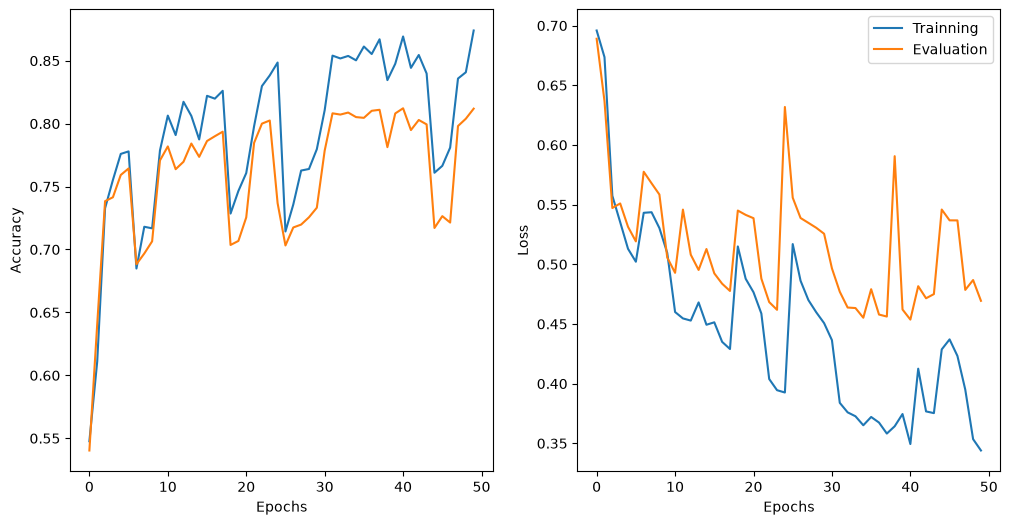

In [49]:
plot_result(
    num_epochs,
    metrics["train_accuracy"],
    metrics["valid_accuracy"],
    metrics["train_loss"],
    metrics["valid_loss"]
)

In [50]:
def inference(sentence, vocabulary, model, device):
    sentence = preprocess_text(sentence)
    encoded_sentence = vocabulary(tokenizer(sentence))
    encoded_sentence = torch.tensor([encoded_sentence])
    encoded_sentence = encoded_sentence.to(device)

    with torch.no_grad():
        predictions = model(encoded_sentence, device)
    preds = nn.Softmax(dim=1)(predictions)
    p_max, yhat = torch.max(preds.data, 1)

    return round(p_max.item(), 2)*100, yhat.item()

In [51]:
inference(sentence='quán ăn dở quá', vocabulary=vocabulary, model=model, device=device)

(89.0, 0)